# RWB «Отгрузки без простоев» — решение, версия 3

Прогноз `target_1h` на 8 получасов вперёд для 1000 маршрутов от точки 01.11.2025 10:30. Метрика — **WAPE + |Relative Bias|**, меньше — лучше.

| | 14 дней валидации | перекрёстно | лидерборд |
|---|---|---|---|
| Baseline организаторов (Ridge) | 0.3674 | — | — |
| v1: XGBoost + Huber + MLP (`solution_v1.ipynb`) | 0.3269 | 0.3291 | 0.324 |
| v2: + seed'ы + Tweedie (`solution_v2.ipynb`) | 0.3268 | 0.3288 | 0.323 |
| **v3: сглаженные профили маршрутов (этот ноутбук)** | **0.3249** | **0.3249** | — |

«Перекрёстно» — коэффициенты ансамбля подобраны на одной неделе и проверены на другой; это честная оценка переноса на новый день.

**Что нового в v3.** У каждой модели раньше был «сезонный ориентир» — среднее того же получаса за 7 дней (`slot7`) и за 14 дней. Он шумный: 7 точек на маршрут. В v3 для каждого маршрута строится **профиль дня за 28 дней**, и профили всех 1000 маршрутов сглаживаются **малоранговым разложением (SVD, ранг 12)**. Общие для многих маршрутов формы дня остаются, индивидуальный шум уходит. Этот профиль используется и как признак, и как половина базы прогноза: модель учит поправку уже к нему. Идея — из решения победителя Walmart (Kaggle), где малоранговое сглаживание по магазинам дало лучшую одиночную модель.

Ноутбук «тонкий»: код в `src/rwb/` и `scripts/`. Тяжёлые шаги берут сохранённые предсказания из `models/oof/`; `RETRAIN = True` пересчитывает всё (≈2 часа на RTX 4060 Laptop).

1. Данные и валидация (кратко)
2. Новая идея: профили маршрутов и их сглаживание
3. Что проверено при поиске и что сработало
4. Модели v3
5. Ансамбль
6. Подтверждение на третьей неделе
7. Разбор ошибок
8. Итоговый прогноз

In [1]:
import sys, itertools, time, logging
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent  # запуск из notebooks/
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "scripts"))

from rwb.data import HORIZON, load_panel, make_submission
from rwb.features import DAY, cumsums, lowrank_profiles
from rwb.backtest import default_folds, run, score_origins, truth_for
from rwb.models import GBMConfig, gbm_fit_predict, naive

logging.basicConfig(level=logging.INFO, format="%(asctime)s %(name)s %(message)s", datefmt="%H:%M:%S")
RETRAIN = False
OOF = ROOT / "models/oof"
OOF.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 160)

## 1. Данные и валидация — кратко

1000 маршрутов × 4630 получасов (28.07–01.11.2025 10:30), шесть статусов и `target_1h` — объём за последний час. `target_1h[t] = x[t] + x[t-1]`, получасы `x` восстанавливаются точно (см. `solution_v1.ipynb`). Валидация: прогноз от 10:30 в каждый из 14 предыдущих дней, две недели — два фолда, обучение только на метках до первой точки фолда. Третья, более ранняя неделя используется в разделе 6 как контроль, которая в отборе вариантов не участвовала.

In [2]:
panel = load_panel()
cums = cumsums(panel)
folds = default_folds(panel)
for f in folds:
    print(f"{f.name}: обучение на метках до {panel.times[f.label_cutoff]}, валидация {panel.times[f.val_origins[0]].date()} … {panel.times[f.val_origins[-1]].date()}")

fold0: обучение на метках до 2025-10-25 10:30:00, валидация 2025-10-25 … 2025-10-31
fold1: обучение на метках до 2025-10-18 10:30:00, валидация 2025-10-18 … 2025-10-24


## 2. Профили маршрутов и их сглаживание

Для точки прогноза `o` и каждого из следующих 48 получасов `j` профиль маршрута — среднее `target_1h` в тот же получас за последние 28 дней (`rwb.features.lowrank_profiles`). Получаем матрицу 1000 маршрутов × 48 получасов. Каждую строку делим на её среднее (форма дня без масштаба маршрута), раскладываем матрицу SVD и оставляем 12 главных компонент. Всё считается только по прошлому относительно `o`; тест на утечки в `tests/test_features.py` это проверяет.

Ниже — сколько разброса форм дня объясняют первые компоненты, и как выглядит профиль для одного маршрута.

доля разброса форм дня, объяснённая первыми k компонентами:
{1: 0.98, 3: 0.986, 6: 0.99, 12: 0.994, 20: 0.997}


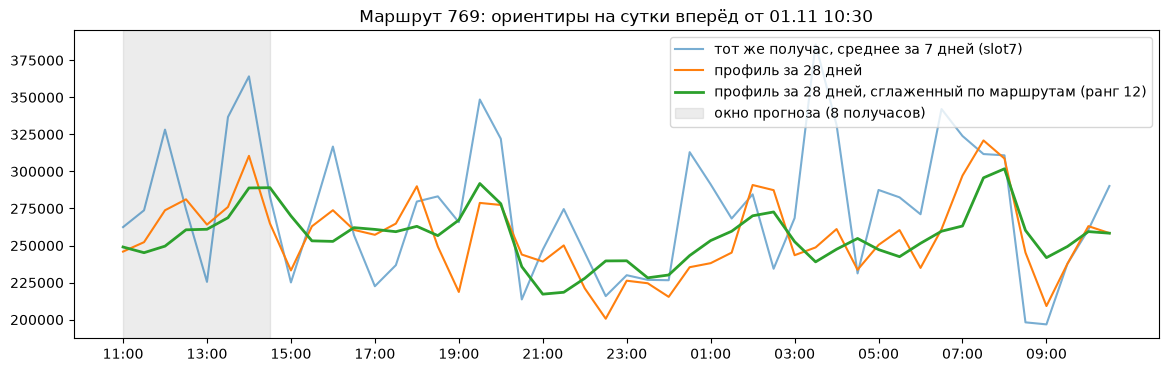

In [3]:
o = np.array([panel.n_times - 1])
prof, smooth = lowrank_profiles(panel.y, o, rank=12)
shape = prof[0] / (prof[0].mean(axis=1, keepdims=True) + 1)
s = np.linalg.svd(shape, compute_uv=False)
share = (s ** 2).cumsum() / (s ** 2).sum()
print("доля разброса форм дня, объяснённая первыми k компонентами:")
print({k: round(float(share[k - 1]), 3) for k in (1, 3, 6, 12, 20)})

r = int(np.argsort(np.nan_to_num(panel.y).mean(1))[500])     # маршрут со срединным объёмом
t = o[0] + np.arange(1, DAY + 1)
slot7 = np.mean([panel.y[r, t - k * DAY] for k in range(1, 8)], axis=0)
hours = (panel.times[o[0]] + pd.to_timedelta(30 * np.arange(1, DAY + 1), unit="min")).strftime("%H:%M")
xs = np.arange(DAY)
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(xs, slot7, label="тот же получас, среднее за 7 дней (slot7)", alpha=.6)
ax.plot(xs, prof[0, r], label="профиль за 28 дней")
ax.plot(xs, smooth[0, r], label="профиль за 28 дней, сглаженный по маршрутам (ранг 12)", lw=2)
ax.axvspan(0, 7, color="grey", alpha=.15, label="окно прогноза (8 получасов)")
ax.set_xticks(xs[::4], hours[::4]); ax.legend(); ax.set_title(f"Маршрут {panel.routes[r]}: ориентиры на сутки вперёд от 01.11 10:30")
plt.show()

## 3. Что проверено при поиске и что сработало

Перед v3 был сделан разбор важности признаков (перемешивание группы на валидации и рост ошибки). Почти весь сигнал — в последних восстановленных получасах `x` и статусах 2–3 (заказы на подходе к отгрузке); статусы 4–6 и ряд групп не влияют вовсе. Затем проверены идеи из статей и разборов соревнований (VN1, M5, Walmart, Favorita); все числа — на одной валидации с быстрой моделью XGBoost, «перекрёстно».

| Идея | Перекрёстно | Итог |
|---|---|---|
| Быстрая модель XGBoost без изменений | 0.3303 | эталон |
| Ошибка сезонной базы в прошлые дни как признак | хуже | — |
| Отношения «сегодня / вчера / неделю назад» на длинных окнах | так же | — |
| Динамика статусов 1–3 по шагам | так же | — |
| Выкинуть бесполезные признаки (статусы 4–6 и др.) | хуже | — |
| Окно обучения 14 / 21 день, их смесь с 28 | хуже, вес в смеси 0 | — |
| Отдельные модели для мелких / средних / крупных маршрутов | 0.0002 в смеси | — |
| Модель суммы за 4 часа + согласование 8 шагов с ней | хуже | — |
| Учёт рабочей субботы 01.11 | в отгрузках эффекта нет | — |
| **Профиль за 28 дней как признак**, без сглаживания | 0.3284 | помогает |
| **+ сглаживание по маршрутам**, ранг 3 / 6 / 12 / 20 / 30 | 0.3277 / 0.3272 / **0.3267** / 0.3273 / 0.3274 | ранг 12 |
| Профиль за 42 дня вместо 28 | 0.3262 (с базой) | хуже 28 дней |
| **Профиль ранга 12 ещё и в базе прогноза** | **0.3256** | лучшее |
| Профиль × уровень последних суток (мультипликативная база) | 0.3306 | хуже |

Коэффициенты ансамбля тоже проверены: перебор 1771 сочетания, равные веса, бутстреп, геометрическое среднее, веса по горизонтам. Поверхность почти плоская, обычный подбор оптимизатором не хуже остальных.

## 4. Модели v3

Все модели обучаются с признаками профиля (`feat_sets="lowrank12"`); у XGBoost и Huber профиль ещё и в базе (`base="lowrank"`). Tweedie предсказывает объём напрямую, база ему не нужна.

| Член ансамбля | Из чего | Что это |
|---|---|---|
| `xgb_blr_bag3` | `xgb_lr_blr_s0..s2` | XGBoost (GPU), L1, по модели на горизонт, 900 деревьев, lr 0.02, 63 листа, 28 дней; 3 seed'а усреднены |
| `lgbm_huber_blr` | — | LightGBM, Huber, сильная регуляризация (31 лист, ≥1000 примеров в листе) |
| `lgbm_tweedie_lr12` | — | LightGBM, Tweedie (p = 1.5), цель — объём в долях уровня маршрута |

In [4]:
XGB = dict(lib="xgb", days=28, stride=2, rounds=900, lr=0.02, leaves=63, min_child=200, feat_sets="lowrank12", base="lowrank")
RUNS = {
    "xgb_lr_blr_s0": GBMConfig(**XGB, seed=0), "xgb_lr_blr_s1": GBMConfig(**XGB, seed=1), "xgb_lr_blr_s2": GBMConfig(**XGB, seed=2),
    "lgbm_huber_blr": GBMConfig(lib="lgbm", days=28, stride=4, rounds=400, lr=0.05, leaves=31, min_child=1000, objective="huber",
                                feat_sets="lowrank12", base="lowrank", extra={"num_threads": 8, "alpha": 1.0}),
    "lgbm_tweedie_lr12": GBMConfig(lib="lgbm", days=28, stride=4, rounds=600, lr=0.05, leaves=31, min_child=1000, objective="tweedie",
                                   target="ratio", feat_sets="lowrank12", extra={"num_threads": 8, "tweedie_variance_power": 1.5}),
}
MEMBERS = {"xgb_blr_bag3": ["xgb_lr_blr_s0", "xgb_lr_blr_s1", "xgb_lr_blr_s2"],
           "lgbm_huber_blr": ["lgbm_huber_blr"], "lgbm_tweedie_lr12": ["lgbm_tweedie_lr12"]}

def backtest(name):
    path = OOF / f"{name}.npz"
    if path.exists() and not RETRAIN:
        z = np.load(path)
        return {f.name: z[f"pred_{f.name}"] for f in folds}, {f.name: z[f"truth_{f.name}"] for f in folds}
    t0 = time.time()
    res = run(panel, folds, lambda f: gbm_fit_predict(panel, cums, f.label_cutoff, f.val_origins, RUNS[name]))
    np.savez_compressed(path, **{f"pred_{k}": v for k, v in res.preds.items()}, **{f"truth_{k}": v for k, v in res.truth.items()})
    print(f"{name}: {time.time() - t0:.0f} c")
    return res.preds, res.truth

run_preds, truth = {}, None
for r in RUNS:
    run_preds[r], truth = backtest(r)
preds = {m: {f: np.mean([run_preds[r][f] for r in rs], axis=0) for f in truth} for m, rs in MEMBERS.items()}

from ensemble import best_scale  # scripts/ensemble.py
rows = []
for name in list(RUNS) + ["xgb_blr_bag3"]:
    src = run_preds.get(name) or preds[name]
    P = np.concatenate([src[f] for f in sorted(truth)]); Y = np.concatenate([truth[f] for f in sorted(truth)])
    k, s = best_scale(P, Y)
    rows.append({"модель": name, **{f"{f} без калибровки": np.mean(score_origins(src[f], truth[f])) for f in sorted(truth)},
                 "множитель": k, "14 дней с множителем": s})
pd.DataFrame(rows).set_index("модель").round(4)

,fold0 без калибровки,fold1 без калибровки,множитель,14 дней с множителем
модель,,,,
xgb_lr_blr_s0,0.3320,0.3312,1.0125,0.3251
xgb_lr_blr_s1,0.3322,0.3311,1.0125,0.3251
xgb_lr_blr_s2,0.3323,0.3310,1.0125,0.3251
lgbm_huber_blr,0.3279,0.3264,0.9925,0.3258
lgbm_tweedie_lr12,0.3299,0.3276,0.9925,0.3264
xgb_blr_bag3,0.3321,0.3310,1.0125,0.3250


Множитель у XGBoost с профилем в базе — около 1.01 вместо 1.02 в v2: с лучшим ориентиром модель меньше занижает сумму. Tweedie и Huber теперь чуть завышают (множитель 0.99).

## 5. Ансамбль

Два способа смешать три модели (`scripts/ensemble.py`), оба с перекрёстной оценкой по неделям:
- **подбирать доли** оптимизатором вместе с множителем, как в v1/v2;
- **зафиксировать доли** 0.8 / 0.1 / 0.1 и подбирать только множитель (`--shares 0.8,0.1,0.1`).

С новыми моделями подобранные доли «прыгают» между неделями (на одной почти всё отдаётся XGBoost, на другой — Tweedie), и это стоит точности на другой неделе. Фиксированные доли — один свободный параметр вместо трёх; перебор долей 1/0/0 … 0.33/0.33/0.33 показал плато 0.3249–0.3250 для долей XGBoost 0.7–0.9.

In [5]:
from ensemble import fit_weights

NAMES = list(MEMBERS)
SHARES = np.array([0.8, 0.1, 0.1])
fold_names = sorted(truth)
P = {f: np.stack([preds[n][f] for n in NAMES], axis=-1) for f in fold_names}
for label, sh in [("доли подбираются", None), ("доли 0.8/0.1/0.1, подбирается множитель", SHARES)]:
    cross = []
    for fit_f, eval_f in itertools.permutations(fold_names, 2):
        w, _ = fit_weights(P[fit_f], truth[fit_f], per_h_scale=False, shares=sh)
        cross.append(np.mean(score_origins(P[eval_f] @ w, truth[eval_f])))
        print(f"  [{label}] с {fit_f} → на {eval_f}: {cross[-1]:.4f}   коэффициенты {np.round(w, 3)}")
    print(f"{label}: перекрёстно {np.mean(cross):.4f}\n")
P_all = np.concatenate([P[f] for f in fold_names]); Y_all = np.concatenate([truth[f] for f in fold_names])
W, _ = fit_weights(P_all, Y_all, per_h_scale=False, shares=SHARES)
print(f"итоговые коэффициенты: {dict(zip(NAMES, np.round(W, 3)))}, множитель = {W.sum():.4f}")
print(f"на 14 днях: {np.mean(score_origins(P_all @ W, Y_all)):.4f}")

  [доли подбираются] с fold0 → на fold1: 0.3245   коэффициенты [0.882 0.064 0.064]


  [доли подбираются] с fold1 → на fold0: 0.3268   коэффициенты [0.231 0.101 0.666]
доли подбираются: перекрёстно 0.3256

  [доли 0.8/0.1/0.1, подбирается множитель] с fold0 → на fold1: 0.3244   коэффициенты [0.806 0.101 0.101]
  [доли 0.8/0.1/0.1, подбирается множитель] с fold1 → на fold0: 0.3253   коэффициенты [0.806 0.101 0.101]
доли 0.8/0.1/0.1, подбирается множитель: перекрёстно 0.3249

итоговые коэффициенты: {'xgb_blr_bag3': np.float64(0.806), 'lgbm_huber_blr': np.float64(0.101), 'lgbm_tweedie_lr12': np.float64(0.101)}, множитель = 1.0075
на 14 днях: 0.3249


## 6. Подтверждение на третьей неделе

При поиске сравнивалось много вариантов на двух неделях, и часть «прироста» могла оказаться удачей отбора. Поэтому быструю модель с профилями и без них прогнали ещё на третьей, более ранней неделе. Множитель подбирается на неделях 0–1, неделя 2 — контрольная.

In [6]:
ks = np.arange(0.97, 1.06, 0.0025)
rows = []
for n, lab in [("xgb_base3", "без профилей"), ("xgb_lowrank3", "профиль как признак (ранг 6)"), ("xgb_blr3", "профиль в базе + признак (ранг 12)")]:
    path = OOF / f"{n}.npz"
    if not path.exists():
        print(f"{n}: нет сохранённых предсказаний — запустите scripts/experiment.py с --folds 3"); continue
    z = np.load(path)
    P01 = np.concatenate([z["pred_fold0"], z["pred_fold1"]]); Y01 = np.concatenate([z["truth_fold0"], z["truth_fold1"]])
    k = ks[np.argmin([np.mean(score_origins(P01 * k, Y01)) for k in ks])]
    rows.append({"вариант": lab, "множитель (недели 0–1)": k,
                 **{f"неделя {i}": np.mean(score_origins(z[f"pred_fold{i}"] * k, z[f"truth_fold{i}"])) for i in range(3)}})
pd.DataFrame(rows).set_index("вариант").round(4)

,множитель (недели 0–1),неделя 0,неделя 1,неделя 2
вариант,,,,
без профилей,1.0225,0.3298,0.3253,0.3336
профиль как признак (ранг 6),1.0150,0.3273,0.3253,0.3330
профиль в базе + признак (ранг 12),1.0100,0.3257,0.3255,0.3324


## 7. Разбор ошибок

WAPE по дням стабилен, смещение суммы по дням непредсказуемо (±0.01–0.05) — это по-прежнему главный предел. По сравнению с v2 (средний WAPE 0.3146, средний |bias| 0.0122) прирост v3 в основном пришёл из смещения суммы: модели с профилем точнее угадывают дневной объём маршрутов, а точечная ошибка улучшилась немного. Смещение одного дня шумное, поэтому на лидерборде (один день) прирост может оказаться меньше, чем на валидации.

In [7]:
origins = np.concatenate([f.val_origins for f in folds])
blend = P_all @ W
rows = []
for i, o_ in enumerate(origins):
    p, y = blend[i], Y_all[i]
    wape = np.abs(p - y).sum() / y.sum(); rb = (p.sum() - y.sum()) / y.sum()
    rows.append({"день": panel.times[o_].strftime("%Y-%m-%d %a"), "WAPE": wape, "RelBias": rb, "score": wape + abs(rb)})
df = pd.DataFrame(rows).set_index("день")
print(f"средний WAPE {df.WAPE.mean():.4f}  средний |bias| {df.RelBias.abs().mean():.4f}  score {df.score.mean():.4f}")
print("WAPE по горизонтам:", np.round([np.mean([np.abs(blend[i][:, h] - Y_all[i][:, h]).sum() / Y_all[i][:, h].sum()
                                                 for i in range(len(origins))]) for h in range(HORIZON)], 3))
df.round(4)

средний WAPE 0.3143  средний |bias| 0.0105  score 0.3249
WAPE по горизонтам: [0.23  0.301 0.317 0.32  0.338 0.345 0.335 0.334]


,WAPE,RelBias,score
день,,,
2025-10-25 Sat,0.3199,-0.0008,0.3207
2025-10-26 Sun,0.3229,-0.0084,0.3313
2025-10-27 Mon,0.3196,-0.0066,0.3262
2025-10-28 Tue,0.3137,-0.0121,0.3258
2025-10-29 Wed,0.3211,0.0303,0.3515
2025-10-30 Thu,0.3032,0.0006,0.3038
2025-10-31 Fri,0.3160,0.0018,0.3178
2025-10-18 Sat,0.3163,-0.0047,0.3210
2025-10-19 Sun,0.3108,-0.0186,0.3294


## 8. Итоговый прогноз

Каждый прогон обучается на всех данных, seed'ы усредняются, члены смешиваются с коэффициентами `W`.

In [8]:
last = panel.n_times - 1
test_runs = {}
for r in RUNS:
    path = OOF / f"{r}_test.npy"
    if path.exists() and not RETRAIN:
        test_runs[r] = np.load(path)
    else:
        test_runs[r] = gbm_fit_predict(panel, cums, last, np.array([last]), RUNS[r])[0]
        np.save(path, test_runs[r])
test_members = np.stack([np.mean([test_runs[r] for r in MEMBERS[m]], axis=0) for m in NAMES], axis=-1)
final = test_members @ W

sub = make_submission(panel, final)
out = ROOT / "submissions/solution_v3_notebook.csv"
sub.to_csv(out, index=False)
assert len(sub) == 8000 and set(sub["id"]) == set(panel.test["id"]) and (sub["y_pred"] >= 0).all() and np.isfinite(sub["y_pred"]).all()
print(f"{out.name}: {len(sub)} строк, сумма прогноза {sub.y_pred.sum():.3e}")
for ref_name in ["ensemble_v3.csv", "ensemble_v2.csv"]:
    ref = ROOT / "submissions" / ref_name
    if ref.exists():
        v = pd.read_csv(ref).set_index("id").loc[sub["id"], "y_pred"].to_numpy()
        print(f"отличие от {ref_name}: средн. |Δ|/y = {np.abs(v - sub.y_pred.to_numpy()).sum() / v.sum():.2e}, сумма {v.sum():.3e}")
sub.head()

solution_v3_notebook.csv: 8000 строк, сумма прогноза 2.186e+09
отличие от ensemble_v3.csv: средн. |Δ|/y = 0.00e+00, сумма 2.186e+09
отличие от ensemble_v2.csv: средн. |Δ|/y = 2.58e-02, сумма 2.222e+09


,id,y_pred
0,0,105487.062071
1,1,130078.613426
2,2,161365.741415
3,3,158227.687555
4,4,146295.094054


**Оговорка про сумму.** Сумма прогноза v3 примерно на 1–1.5% ниже, чем у v2, потому что новые модели на валидации почти не занижают и множитель у них около 1.0 вместо 1.02. Это подтверждено на трёх неделях, но тестовый день один, и дневное смещение суммы непредсказуемо в пределах ±1–5%.